# 02 — Train/test split, binning, Weight of Evidence and Information Value

This notebook turns raw columns into the inputs a bank scorecard uses:

1. **Split** customers into training (70%) and test (30%) sets.
2. **Build behavioural features** that summarise six months of behaviour.
3. **Bin** each variable: fine classing first, then merge into coarse bins.
4. Replace each bin by its **Weight of Evidence (WoE)** and rank variables by **Information Value (IV)**.

Everything is learned on the **training set only**. The test set is transformed with the bins learned on training
data, and isn't looked at again until validation.

In [1]:
import logging
import warnings

import pandas as pd
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
RATE_FORMAT = {"default_rate": "{:.1%}", "share": "{:.1%}", "woe": "{:+.3f}", "iv": "{:.4f}"}

from scorecard.binning import all_binning_tables, fit_all, iv_table, save_binnings, transform_all
from scorecard.data import MODELS_DIR, PROCESSED_DIR, REPORTS_DIR, clean, load_raw, save_processed, split_train_test
from scorecard.eda import plot_default_rate
from scorecard.features import BIN_SPECS, CANDIDATES, FEATURE_TYPES, add_behavioural_features
from scorecard.plots import plot_iv

## 1. Split first

The split happens **before** any binning, so no decision can be influenced by the test customers.
It is **stratified**: both sets keep the same 22.1% default rate. The seed (42) makes the split identical every run.

In [2]:
df = add_behavioural_features(clean(load_raw()))
train, test = split_train_test(df, test_size=0.3, seed=42)
save_processed(train, PROCESSED_DIR / "train.csv")
save_processed(test, PROCESSED_DIR / "test.csv")

INFO scorecard.data: Loaded 30000 rows x 25 columns from D:\Projects\Credit_analysis\data\raw\credit_card_default.csv


INFO scorecard.data: EDUCATION: recoded 345 values [0, 5, 6] -> 4


INFO scorecard.data: MARRIAGE: recoded 54 values [0] -> 3


INFO scorecard.data: Integrity check passed: 30000 unique customers, no missing values


INFO scorecard.features: Added behavioural features; no balance due: 3175 (pay_ratio_1), 1406 (avg_pay_ratio_6m)


INFO scorecard.data: Train: 21000 customers, default rate 22.12% | Test: 9000 customers, default rate 22.12%


INFO scorecard.data: Saved 21000 rows to D:\Projects\Credit_analysis\data\processed\train.csv


INFO scorecard.data: Saved 9000 rows to D:\Projects\Credit_analysis\data\processed\test.csv


## 2. Candidate variables

Six monthly snapshots of the same measure are noisy and repeat each other. Banks summarise them into *behaviour*:
how late, how full the card is, how much of the bill gets paid. The table lists every candidate and the type of
behaviour it captures. `sex`, `marriage` and `id` are **not** candidates (see `CLAUDE.md`).

How the new features are defined:
- **Utilisation** = bill ÷ credit limit: how "full" the card is. 0.9 means 90% of the limit is used.
- **Payment ratio** = payment in a month ÷ the previous month's bill, capped at 1. If no bill was due (zero or negative),
  the ratio is left empty ("no balance due") and gets its own bin, rather than an invented number.
- `max_delinquency_6m` (worst status), `months_delinquent_6m` (months 1+ late), `months_zero_payment_6m` (months with no payment).

In [3]:
pd.Series(FEATURE_TYPES, name="type").rename_axis("variable").reset_index().groupby("type")["variable"].apply(", ".join).to_frame()

,variable
type,
delinquency,"pay_1, pay_2, pay_3, pay_4, pay_5, pay_6, max_delinquency_6m, months_delinquent_6m"
demographic,"age, education"
limit,limit_bal
payment,"pay_ratio_1, avg_pay_ratio_6m, months_zero_payment_6m, pay_amt1, pay_amt2, pay_amt3, pay_amt4, pay_amt5, pay_amt6"
utilisation,"util_1, avg_util_6m, max_util_6m, util_trend, bill_amt1, bill_amt2, bill_amt3, bill_amt4, bill_amt5, bill_amt6"


## 3. Binning, WoE and IV

**Fine classing:** each numeric variable is cut into about 20 groups with equal numbers of customers.
Repayment status, age and education use business-rule bins instead (e.g. status -2, -1, 0, 1, 2, 3+).

**Coarse classing:** neighbouring bins are merged until
- every bin holds **at least 5% of customers**, so its default rate isn't just noise; and
- for amounts and ratios, the default rate **moves in one direction** from bin to bin (monotonic).
  "Higher utilisation → higher risk" should hold everywhere, without zig-zags that only fit this sample.

**Weight of Evidence** for a bin = ln(% of all goods in the bin ÷ % of all bads in the bin).
- WoE > 0: the bin has relatively more good customers → **safer** than average.
- WoE < 0: relatively more bad customers → **riskier**.

**Information Value** adds up, over all bins, (% goods − % bads) × WoE. It measures how well the variable as a whole
separates goods from bads. The usual rule of thumb:

| IV | Strength |
|---|---|
| < 0.02 | useless |
| 0.02 – 0.1 | weak |
| 0.1 – 0.3 | medium |
| 0.3 – 0.5 | strong |
| > 0.5 | suspicious: check for leakage |

In [4]:
logging.getLogger("scorecard.binning").setLevel(logging.WARNING)  # one line per variable is too chatty here
binnings = fit_all(train, CANDIDATES, BIN_SPECS)
ivs = iv_table(binnings, FEATURE_TYPES)
ivs.to_csv(REPORTS_DIR / "iv_table.csv", index=False)
all_binning_tables(binnings).to_csv(REPORTS_DIR / "binning_tables.csv", index=False)
save_binnings(binnings, MODELS_DIR / "binnings.pkl")  # bin edges, needed to score new customers
ivs.style.format({"iv": "{:.3f}"})

,variable,iv,strength,n_bins,type
0,pay_1,0.894,suspicious,5,delinquency
1,months_delinquent_6m,0.878,suspicious,4,delinquency
2,max_delinquency_6m,0.792,suspicious,5,delinquency
3,pay_2,0.557,suspicious,4,delinquency
4,pay_3,0.420,strong,4,delinquency
5,pay_4,0.368,strong,4,delinquency
6,pay_5,0.343,strong,4,delinquency
7,pay_6,0.296,medium,4,delinquency
8,months_zero_payment_6m,0.263,medium,3,payment
9,pay_ratio_1,0.244,medium,5,payment


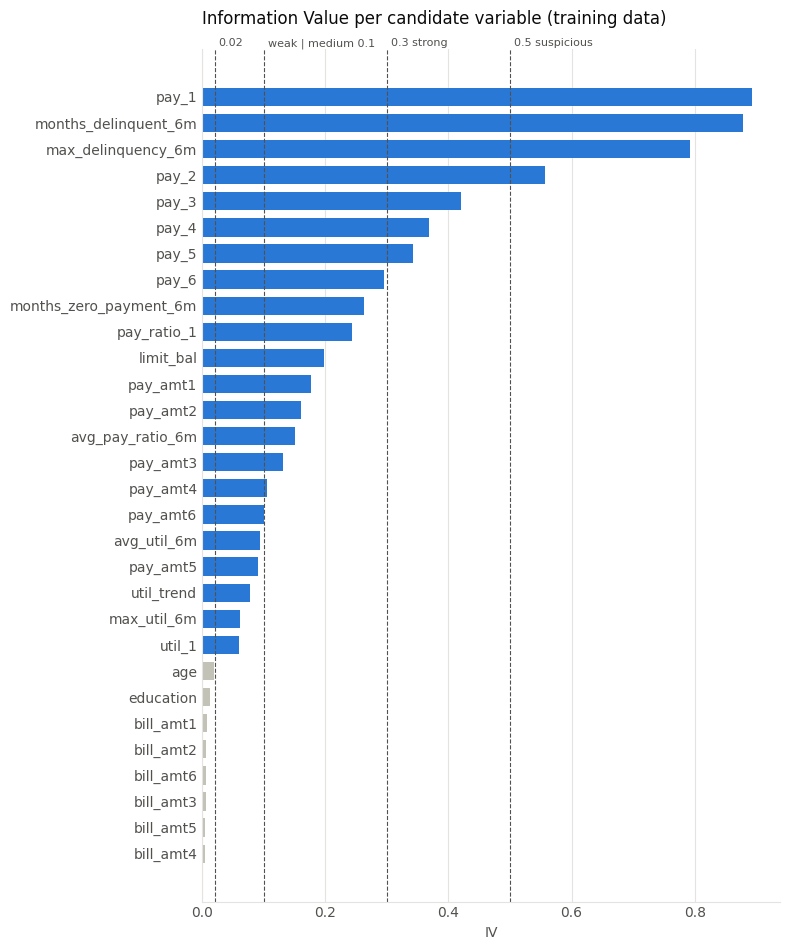

In [5]:
plot_iv(ivs)
plt.show()

What the IV ranking says:
- **Delinquency dominates.** `pay_1` (0.89), `months_delinquent_6m` (0.88) and `max_delinquency_6m` (0.79) are the strongest.
  How a customer has *been* paying predicts how they *will* pay.
- **"Suspicious" (> 0.5) is genuine here, not leakage.** Normally an IV this high suggests a variable that secretly contains
  the outcome. Here `pay_1` is measured in September and the target in October. They are different months, but only one month apart,
  so recent arrears are naturally very predictive. With a 12-month outcome window, as banks normally use, these IVs would be lower.
- **Payment behaviour is medium:** `months_zero_payment_6m`, `pay_ratio_1`, `avg_pay_ratio_6m` and the payment amounts.
- **Utilisation is weak (0.06–0.10), and raw bill amounts are useless (< 0.01).** A NT$50,000 balance is very different
  on a 60,000 limit than on a 500,000 limit, so what matters is the balance *relative to the limit*.
- **Age (0.019) and education (0.013) are useless** as predictors. That settles them on the numbers as well as on fairness grounds.

## 4. Inside the bins: a few key variables

Each table shows, per bin: customers, goods, bads, default rate, share of customers, WoE and its IV contribution.

In [6]:
binnings["pay_1"].table.style.format(RATE_FORMAT)

,customers,goods,bads,default_rate,share,woe,iv
bin,,,,,,,
<= -2,1933,1689,244,12.6%,9.2%,+0.676,0.0343
-1,3971,3297,674,17.0%,18.9%,+0.329,0.0186
0,10285,8985,1300,12.6%,49.0%,+0.674,0.1818
1,2616,1721,895,34.2%,12.5%,-0.605,0.0529
>= 2,2195,663,1532,69.8%,10.5%,-2.096,0.6064


- On-time statuses (-2, -1, 0) all have positive WoE (safer). Statuses 3–8 were too small on their own,
  so they merged into **">= 2"** (2+ months late): about 70% default, WoE −2.1.
- Most of `pay_1`'s IV comes from that single bin. A small group with a very high default rate separates goods from bads strongly.

In [7]:
binnings["pay_2"].table.style.format(RATE_FORMAT)

,customers,goods,bads,default_rate,share,woe,iv
bin,,,,,,,
<= -2,2652,2186,466,17.6%,12.6%,+0.287,0.0096
-1,4248,3557,691,16.3%,20.2%,+0.380,0.0261
0 to 1,11010,9264,1746,15.9%,52.4%,+0.410,0.0781
>= 2,3090,1348,1742,56.4%,14.7%,-1.515,0.4433


The status-1 quirk from Step 2 shows up here. In August, status 1 has almost no customers, so the 5% rule merges it into
**"0 to 1"**. The older months are binned the same way.

,customers,goods,bads,default_rate,share,woe,iv
bin,,,,,,,
<= 0,1543,727,816,52.9%,7.3%,-1.374,0.1803
"(0, 0.03643]",1279,998,281,22.0%,6.1%,+0.009,0.0000
"(0.03643, 0.362]",10344,8103,2241,21.7%,49.3%,+0.027,0.0003
> 0.362,5643,4830,813,14.4%,26.9%,+0.523,0.0629
Missing,2191,1697,494,22.5%,10.4%,-0.025,0.0001


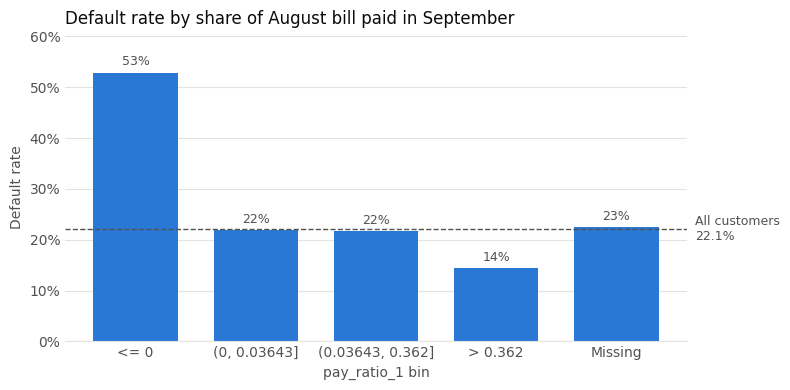

In [8]:
table = binnings["pay_ratio_1"].table
display(table.style.format(RATE_FORMAT))
plot_default_rate(table, "Default rate by share of August bill paid in September", "pay_ratio_1 bin",
                  train["default"].mean())
plt.show()

- Customers who had a bill but **paid nothing** (`<= 0`) default at about 53%.
- Paying more than about a third of the bill → about 14%.
- **Missing = no balance due.** These customers had nothing to pay, and their default rate (about 22.5%) is close to average.
  The separate bin keeps them from being lumped in with non-payers.

,customers,goods,bads,default_rate,share,woe,iv
bin,,,,,,,
<= 30000,2864,1807,1057,36.9%,13.6%,-0.723,0.0846
30001 to 70000,3598,2613,985,27.4%,17.1%,-0.283,0.0148
70001 to 100000,2262,1718,544,24.0%,10.8%,-0.109,0.0013
100001 to 140000,1950,1492,458,23.5%,9.3%,-0.078,0.0006
140001 to 160000,1262,1029,233,18.5%,6.0%,+0.227,0.0029
160001 to 240000,4155,3438,717,17.3%,19.8%,+0.309,0.0172
240001 to 360000,3187,2735,452,14.2%,15.2%,+0.541,0.0379
>= 360001,1722,1523,199,11.6%,8.2%,+0.776,0.0390


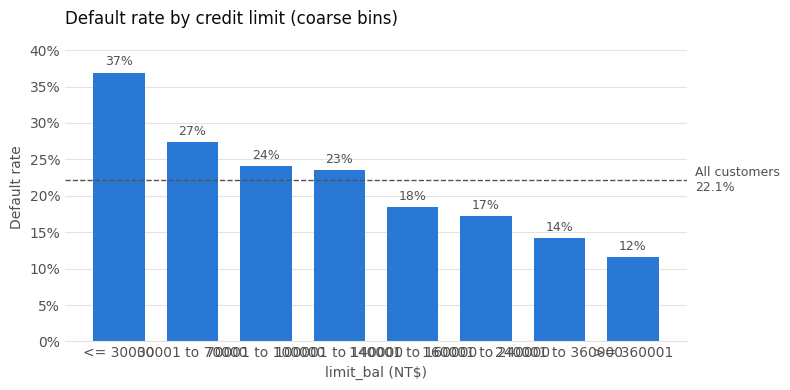

In [9]:
table = binnings["limit_bal"].table
display(table.style.format(RATE_FORMAT))
plot_default_rate(table, "Default rate by credit limit (coarse bins)", "limit_bal (NT$)", train["default"].mean())
plt.show()

Eight bins whose default rate falls steadily from about 37% to about 12% as the limit rises: monotonic, as required.

## 5. WoE-transform train and test

Every value is replaced by the WoE of its bin. The test set uses the bins and WoE values **learned on training data**.
That is exactly what will happen to new customers in real use.

In [10]:
train_woe = transform_all(train, binnings)
test_woe = transform_all(test, binnings)
save_processed(train_woe, PROCESSED_DIR / "train_woe.csv")
save_processed(test_woe, PROCESSED_DIR / "test_woe.csv")
train_woe.head()

INFO scorecard.data: Saved 21000 rows to D:\Projects\Credit_analysis\data\processed\train_woe.csv


INFO scorecard.data: Saved 9000 rows to D:\Projects\Credit_analysis\data\processed\test_woe.csv


,id,pay_1,pay_2,pay_3,pay_4,pay_5,pay_6,max_delinquency_6m,months_delinquent_6m,util_1,avg_util_6m,max_util_6m,util_trend,bill_amt1,bill_amt2,...,bill_amt5,bill_amt6,pay_ratio_1,avg_pay_ratio_6m,months_zero_payment_6m,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,limit_bal,age,education,default
11018,11019,0.674450,0.410066,0.289457,0.228802,0.204829,0.199862,0.874766,0.786619,-0.223471,-0.582690,-0.204507,0.246432,0.169752,0.160618,...,0.115690,-0.062856,0.026570,-0.432986,0.579828,0.442633,0.451316,0.410502,0.433538,0.343473,0.409501,0.226562,0.130604,-0.083675,0
1710,1711,0.674450,0.410066,0.289457,0.228802,-1.508832,0.199862,-1.132258,-0.408839,0.103910,0.098051,0.063315,-0.425013,-0.048339,-0.054804,...,0.111754,-0.062856,0.026570,-0.017178,-0.381044,0.300558,0.451316,0.652077,-0.447164,-0.014322,0.016753,-0.108775,0.113163,0.160746,1
4618,4619,0.674450,0.410066,0.289457,0.228802,0.204829,0.199862,0.874766,0.786619,-0.223471,-0.195376,-0.204507,0.246432,0.080595,0.040541,...,-0.028794,-0.062856,0.026570,-0.432986,0.579828,0.048568,0.048783,-0.039705,-0.008540,-0.014322,0.016753,-0.108775,0.113163,0.160746,0
5482,5483,0.674450,0.410066,0.423769,0.403478,0.207339,0.170237,0.874766,0.786619,0.029264,0.267675,0.200577,0.246432,-0.048339,-0.054804,...,-0.065606,0.091484,0.523128,0.288909,-0.507511,-0.056321,-0.118780,-0.516310,-0.447164,-0.366852,-0.356930,-0.722509,0.113163,-0.083675,0
26187,26188,0.675981,0.286901,0.277892,0.238141,0.207339,0.170237,0.699447,0.786619,0.254740,0.267675,0.234123,-0.084451,-0.134193,-0.054804,...,-0.065606,0.091484,0.523128,0.619665,-0.507511,0.048568,-0.566793,-0.516310,-0.447164,-0.366852,-0.356930,-0.283130,0.113163,0.160746,0
